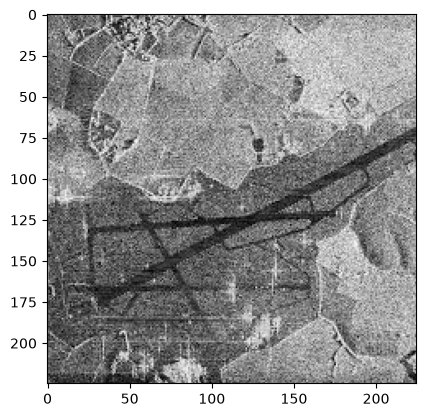

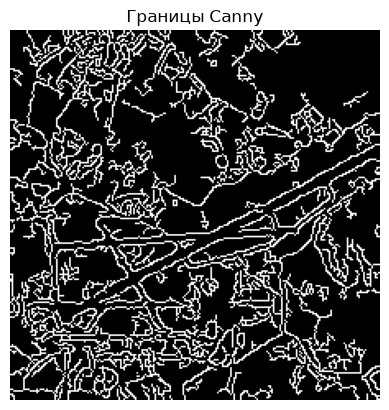

Количество найденных линий: 3
Наиболее протяжённый участок:
Начальная точка: (13, 180)
Конечная точка: (223, 69)
Длина: 237.53 px


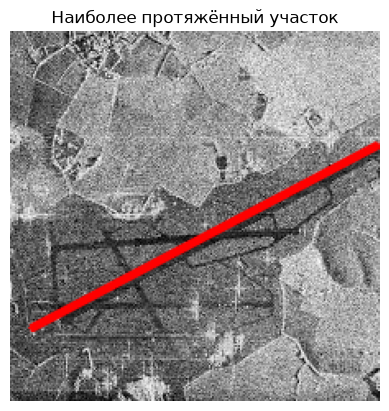

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import math 
import copy

image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image)
plt.show()

# 1. Для изображения sar_3.jpg найти наиболее протяженный участок (выделить линии при помощи преобразования Хафа)
blur = cv2.GaussianBlur(image_gray, (5, 5), 0)
canny = cv2.Canny(blur,50,150,apertureSize = 3)
plt.imshow(canny, cmap='gray')
plt.title('Границы Canny')
plt.axis('off')
plt.show()

lines = cv2.HoughLinesP(canny, 1, np.pi / 180, threshold=100, minLineLength=80, maxLineGap=20)
print('Количество найденных линий:', 0 if lines is None else len(lines))

max_length = 0
best_line = None

if lines is not None:
    lines = lines.reshape(-1, 4)
    for x1, y1, x2, y2 in lines:
        length = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

        if length > max_length:
            max_length = length
            best_line = (
                int(x1),
                int(y1),
                int(x2),
                int(y2)
            )

result = image.copy()

if best_line is not None:
    x1, y1, x2, y2 = best_line
    cv2.line(result,(x1, y1),(x2, y2),(0, 0, 255),3,cv2.LINE_AA)

if best_line is not None:
    print('Наиболее протяжённый участок:')
    print('Начальная точка:', (x1, y1))
    print('Конечная точка:', (x2, y2))
    print('Длина:', round(max_length, 2), 'px')
else:
    print('Участок не найден')

plt.imshow(cv2.cvtColor(result,cv2.COLOR_BGR2RGB))
plt.title('Наиболее протяжённый участок')
plt.axis('off')
plt.show()

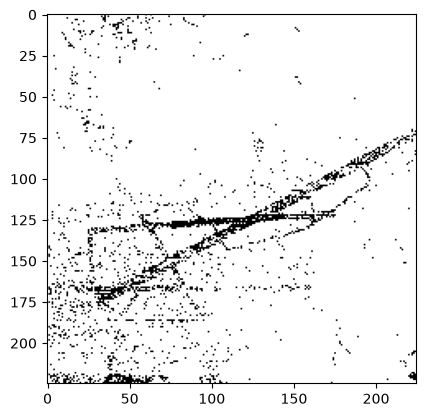

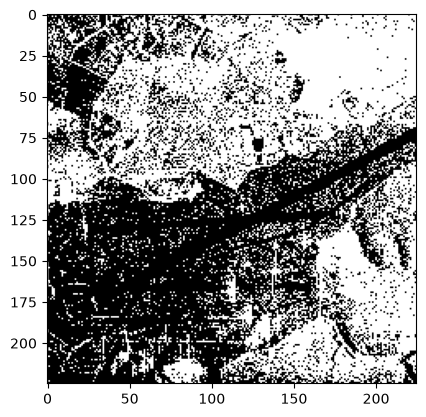

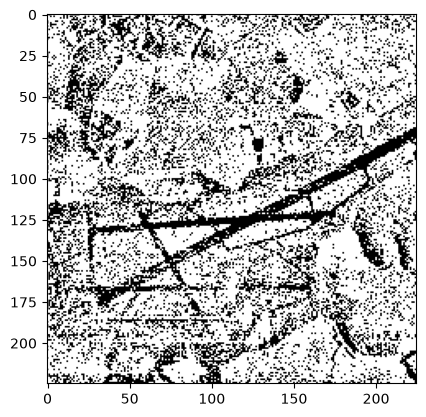

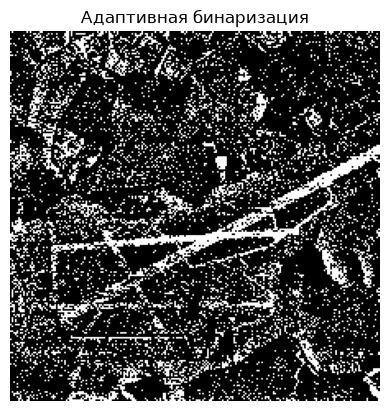

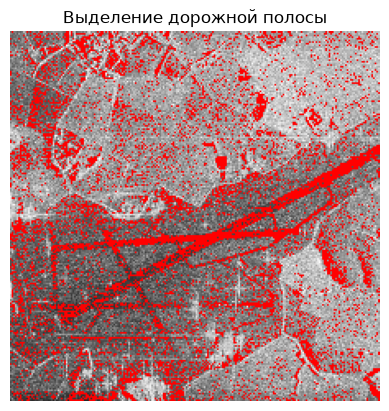

"\nroad_binary = cv2.threshold(image_gray,100,255,cv2.THRESH_BINARY_INV)[1]\nplt.imshow(road_binary, cmap='gray')\nplt.title('Тёмные участки изображения')\nplt.axis('off')\nplt.show()\n\nkernel = np.ones((3, 3), np.uint8)\nroad_binary = cv2.morphologyEx(road_binary,cv2.MORPH_OPEN,kernel)\nroad_binary = cv2.morphologyEx(road_binary,cv2.MORPH_CLOSE,kernel)\n\nroad_mask = road_binary\nroad = cv2.bitwise_and(image_gray,image_gray,mask=road_mask)\n\nplt.imshow(road, cmap='gray')\nplt.title('Выделение дорожной полосы')\nplt.axis('off')\nplt.show()\n\nresult = image.copy()\nresult[road_mask > 0] = (0, 0, 255)\n\nplt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))\nplt.title('Дорожная полоса')\nplt.axis('off')\nplt.show()\n"

In [12]:
# 2. Для изображения sar_3.jpg провести исследование алгоритмов бинаризации, выделить участок дорожной полосы.
# Точечная бинаризация
bin_img = copy.deepcopy(image_gray)
T = 50
bin_img[image_gray < T] = 0
bin_img[image_gray >= T] = 255
plt.imshow(bin_img, cmap="gray")
plt.show()

# Бинаризация Отсу
_,th2 = cv2.threshold(image_gray,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
plt.imshow(th2, cmap="gray")
plt.show()

# Адаптивная бинаризация
th3 = cv2.adaptiveThreshold(image_gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY,71,21)
plt.imshow(th3, cmap="gray")
plt.show()

road_mask = cv2.adaptiveThreshold(
    image_gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY_INV,
    71,
    30
)
plt.imshow(road_mask, cmap="gray")
plt.title("Адаптивная бинаризация")
plt.axis("off")
plt.show()
result = image.copy()

result[road_mask == 255] = (0, 0, 255)

plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Выделение дорожной полосы")
plt.axis("off")
plt.show()

"""
road_binary = cv2.threshold(image_gray,100,255,cv2.THRESH_BINARY_INV)[1]
plt.imshow(road_binary, cmap='gray')
plt.title('Тёмные участки изображения')
plt.axis('off')
plt.show()

kernel = np.ones((3, 3), np.uint8)
road_binary = cv2.morphologyEx(road_binary,cv2.MORPH_OPEN,kernel)
road_binary = cv2.morphologyEx(road_binary,cv2.MORPH_CLOSE,kernel)

road_mask = road_binary
road = cv2.bitwise_and(image_gray,image_gray,mask=road_mask)

plt.imshow(road, cmap='gray')
plt.title('Выделение дорожной полосы')
plt.axis('off')
plt.show()

result = image.copy()
result[road_mask > 0] = (0, 0, 255)

plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title('Дорожная полоса')
plt.axis('off')
plt.show()
"""